In [61]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load and Clean Excel Sheets as DFs:

In [62]:
CO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='CO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
SO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='SO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
NOx_df = pd.read_excel("Emissions2024.xlsx", sheet_name='NOx', header=1, skipfooter=2).query("`Plant Code`!=99999")

# Cast SO2 and NOx Emissions as a Float:

In [109]:
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].replace(' ', 0)
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].astype('float')
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].replace(' ', 0)
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].astype('float')

# Create 'clean' dfs that remove rows with no generation, fuel consumption or emissions:

In [110]:
CO2_clean = CO2_df.query("`Generation (kWh)` > 0 & `Total Fuel Consumption (MMBtu)` > 0 & `Tons of CO2 Emissions` > 0")
SO2_clean = SO2_df.query("`Generation (kWh)` > 0 & `Total Fuel Consumption (MMBtu)` > 0 & `EIA Model Estimates of SO2 Emissions (Tons)` > 0")
NOx_clean = NOx_df.query("`Generation (kWh)` > 0 & `Total Fuel Consumption (MMBtu)` > 0 & `EIA Model Estimates of SO2 Emissions (Tons)` > 0")

# DFs that show columns with 0s for values

In [ ]:
CO2_any_zero = CO2_df.query("`Generation (kWh)` == 0 | `Total Fuel Consumption (MMBtu)` == 0 | `Tons of CO2 Emissions` == 0")
CO2_no_consumption = CO2_df.query("`Total Fuel Consumption (MMBtu)` == 0")
CO2_no_generation = CO2_df.query("`Total Fuel Consumption (MMBtu)` == 0")
CO2_no_emissions = CO2_df.query("`Tons of CO2 Emissions` == 0")

,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Fuel Code,Aggregated Fuel Group,Generation (kWh),Useful Thermal Output (MMBtu),...,Fuel Consumption for Electric Generation (MMBtu),\n Fuel Consumption for Useful Thermal Output (MMBtu),Quantity of Fuel Consumed,Fuel Units,Tons of CO2 Emissions,Metric Tonnes of CO2 Emissions,NERC Region,Balancing Authority Code,Balancing Authority Name,EIA Balancing Authority Region
16,56,Lowman Energy Center,AL,ELECTRIC POWER,1,CA,NG,GAS,1461071000,0,...,0,0,0,Mcf,0,0,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast
29,75,Hank Nikkels Plant 1,AK,ELECTRIC POWER,1,IC,DFO,PET,0,0,...,72,0,12,Barrels,6,5,NaN,NaN,Balancing Authority Not Reported,Alaska
47,117,West Phoenix,AZ,ELECTRIC POWER,1,CA,NG,GAS,564989000,0,...,0,0,0,Mcf,0,0,WECC,AZPS,Arizona Public Service Company,Southwest
61,136,Seminole (FL),FL,ELECTRIC POWER,1,CA,NG,GAS,2802338000,0,...,0,0,0,Mcf,0,0,SERC,SEC,Seminole Electric Cooperative,Florida
76,165,GREC,OK,ELECTRIC POWER,1,CA,NG,GAS,870111000,0,...,0,0,0,Mcf,0,0,MRO,SWPP,Southwest Power Pool,Central
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4852,65773,Star Peak Geothermal Plant,NV,ELECTRIC POWER,2,BT,GEO,GEO,39587000,0,...,135070,0,0,NaN,0,0,WECC,NEVP,Nevada Power Company,Northwest
4855,65978,Dania Beach 7,FL,ELECTRIC POWER,1,CA,NG,GAS,2325652318,0,...,0,0,0,Mcf,0,0,SERC,FPL,Florida Power & Light Co.,Florida
4856,65978,Dania Beach 7,FL,ELECTRIC POWER,1,CA,DFO,PET,4996682,0,...,0,0,0,Barrels,0,0,SERC,FPL,Florida Power & Light Co.,Florida
4925,67380,ERock MID Claribel Generation Station,CA,ELECTRIC POWER,2,IC,NG,GAS,0,0,...,24036,0,20030,Mcf,1402,1272,WECC,BANC,Balancing Authority of Northern California,California


# Create Total Output Columns:

In [120]:
CO2_df['Total Output (MMBtu)'] = (CO2_df['Generation (kWh)'] * .00342) + CO2_df['Useful Thermal Output (MMBtu)']
SO2_df['Total Output (MMBtu)'] = (SO2_df['Generation (kWh)'] * .00342) + SO2_df['Useful Thermal Output (MMBtu)']
NOx_df['Total Output (MMBtu)'] = (NOx_df['Generation (kWh)'] * .00342) + NOx_df['Useful Thermal Output (MMBtu)']

# Replace prime mover values with something interpretable:

In [121]:
pm_replace_map = {'IC': 'Internal Combustion Engine',
'CA': 'Combined Cycle Steam Part',
'CT': 'Combined Cycle Combustion Turbine Part',
'ST': 'Steam Turbine',
'GT': 'Combustion (Gas) Turbine',
'CS': 'Combined Cycle Single Shaft',
'CE': 'Energy Storage, Compressed Air',
'OT': 'Other',
'FC': 'Fuel Cell'
}
 
CO2_df['Prime Mover'] = CO2_df['Prime Mover'].replace(pm_replace_map)
SO2_df['Prime Mover'] = SO2_df['Prime Mover'].replace(pm_replace_map)
NOx_df['Prime Mover'] = NOx_df['Prime Mover'].replace(pm_replace_map)

# EDA:

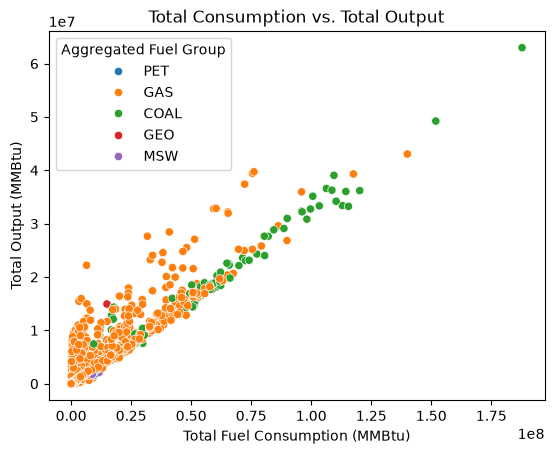

In [112]:
sns.scatterplot(data=CO2_clean, x="Total Fuel Consumption (MMBtu)", y="Total Output (MMBtu)", hue='Aggregated Fuel Group')

plt.title("Total Consumption vs. Total Output")
plt.show()

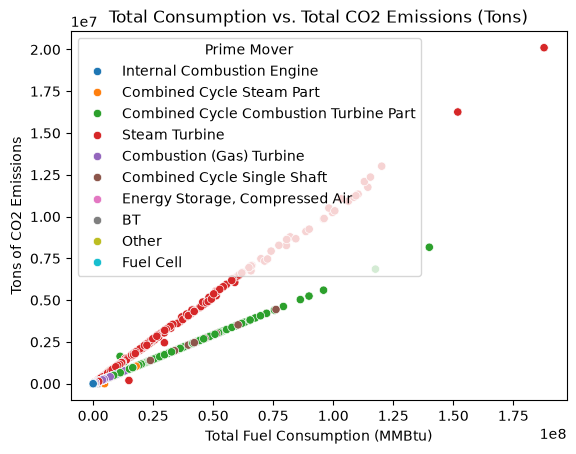

In [129]:
sns.scatterplot(data=CO2_df, x="Total Fuel Consumption (MMBtu)", y="Tons of CO2 Emissions", hue='Prime Mover')

plt.title("Total Consumption vs. Total CO2 Emissions (Tons)")
plt.show()

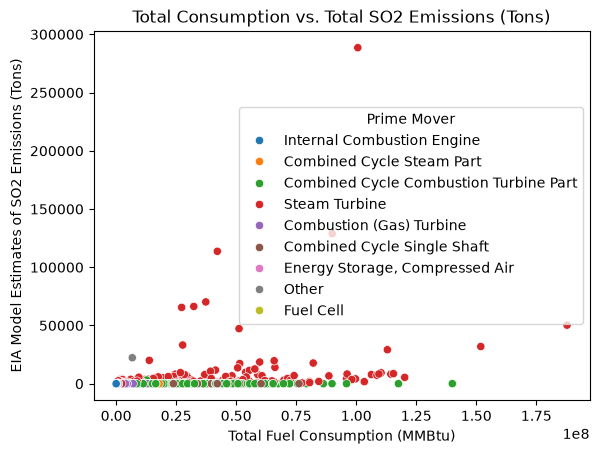

In [127]:
sns.scatterplot(data=SO2_df, x="Total Fuel Consumption (MMBtu)", y="EIA Model Estimates of SO2 Emissions (Tons)", hue='Prime Mover')

plt.title("Total Consumption vs. Total SO2 Emissions (Tons)")
plt.show()

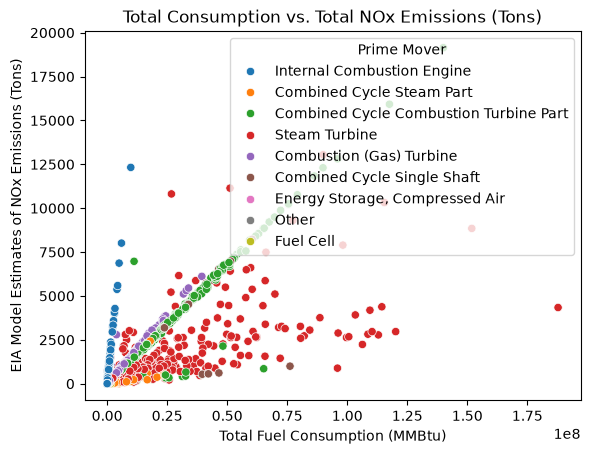

In [130]:
sns.scatterplot(data=NOx_df, x="Total Fuel Consumption (MMBtu)", y="EIA Model Estimates of NOx Emissions (Tons)", hue='Prime Mover')

plt.title("Total Consumption vs. Total NOx Emissions (Tons)")
plt.show()

# Create a unique key column for each DF:

In [ ]:
CO2_df['Plant Code'] = CO2_df['Plant Code'].astype('str')
CO2_df['Sector Code'] = CO2_df['Sector Code'].astype('str')
CO2_df['Plant_Sec_PM_FC'] = CO2_df['Plant Code'] + '_' + CO2_df['Sector Code'] + '_' + CO2_df['Prime Mover'] + '_' + CO2_df['Fuel Code']

In [ ]:
SO2_df['Plant Code'] = SO2_df['Plant Code'].astype('str')
SO2_df['Sector Code'] = SO2_df['Sector Code'].astype('str')
SO2_df['Plant_Sec_PM_FC'] = SO2_df['Plant Code'] + '_' + SO2_df['Sector Code'] + '_' + SO2_df['Prime Mover'] + '_' + SO2_df['Fuel Code']

In [ ]:
NOx_df['Plant Code'] = NOx_df['Plant Code'].astype('str')
NOx_df['Sector Code'] = NOx_df['Sector Code'].astype('str')
NOx_df['Plant_Sec_PM_FC'] = NOx_df['Plant Code'] + '_' + NOx_df['Sector Code'] + '_' + NOx_df['Prime Mover'] + '_' + NOx_df['Fuel Code']

In [ ]:
CO2_df['Plant Code'] = CO2_df['Plant Code'].astype('str')
CO2_df['Sector Code'] = CO2_df['Sector Code'].astype('str')
CO2_df['Plant_Sec_PM_FC'] = CO2_df['Plant Code'] + '_' + CO2_df['Sector Code'] + '_' + CO2_df['Prime Mover']

# Inner Merge Emissions Outputs into one DF:

In [ ]:
result = pd.merge(
    CO2_df, 
    SO2_df[['Plant_Sec_PM_FC', 'EIA Model Estimates of SO2 Emissions (Tons)']], 
    on='Plant_Sec_PM_FC', 
    how='inner'
)

In [ ]:
total_pollution_df = pd.merge(
    result, 
    NOx_df[['Plant_Sec_PM_FC', 'EIA Model Estimates of NOx Emissions (Tons)']], 
    on='Plant_Sec_PM_FC', 
    how='inner'
)

In [ ]:
total_pollution_df.head()

,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Fuel Code,Aggregated Fuel Group,Generation (kWh),Useful Thermal Output (MMBtu),...,Fuel Units,Tons of CO2 Emissions,Metric Tonnes of CO2 Emissions,NERC Region,Balancing Authority Code,Balancing Authority Name,EIA Balancing Authority Region,Plant_Sec_PM_FC,EIA Model Estimates of SO2 Emissions (Tons),EIA Model Estimates of NOx Emissions (Tons)
0,1,Sand Point,AK,ELECTRIC POWER,1,IC,DFO,PET,3616000,0,...,Barrels,3196,2899,NaN,NaN,Balancing Authority Not Reported,Alaska,1_1_IC_DFO,5.006497,58.779979
1,3,Barry,AL,ELECTRIC POWER,1,CA,NG,GAS,4519611000,0,...,Mcf,188829,171303,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,3_1_CA_NG,0.951405,354.67097
2,3,Barry,AL,ELECTRIC POWER,1,CT,NG,GAS,8653458000,0,...,Mcf,5032786,4565672,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,3_1_CT_NG,25.354901,11832.287
3,3,Barry,AL,ELECTRIC POWER,1,ST,BIT,COAL,697528563,0,...,Tons,802806,728294,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,3_1_ST_BIT,273.69221,217.5921
4,3,Barry,AL,ELECTRIC POWER,1,ST,NG,GAS,185271437,0,...,Mcf,156709,142164,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,3_1_ST_NG,0.67211,67.171504


# Remove irrelevant columns in total pollution df:

In [ ]:
nan_cols = total_pollution_df.columns[total_pollution_df.isna().any()].tolist()
print(nan_cols)

['NERC Region', 'Balancing Authority Code']


In [ ]:
total_pollution_df['Fuel Consumption for Useful Thermal Output (MMBtu)'] = total_pollution_df['\n Fuel Consumption for Useful Thermal Output (MMBtu)']

In [ ]:
total_pollution_df.columns

Index(['Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Useful Thermal Output (MMBtu)', 'Total Fuel Consumption (MMBtu)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       '\n Fuel Consumption for Useful Thermal Output (MMBtu)',
       'Quantity of Fuel Consumed', 'Fuel Units', 'Tons of CO2 Emissions',
       'Metric Tonnes of CO2 Emissions', 'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region', 'Plant_Sec_PM_FC',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of NOx Emissions (Tons)',
       'Fuel Consumption for Useful Thermal Output (MMBtu)'],
      dtype='str')

In [ ]:
cols = ['Plant_Sec_PM_FC', 'Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Useful Thermal Output (MMBtu)', 'Total Fuel Consumption (MMBtu)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       'Fuel Consumption for Useful Thermal Output (MMBtu)',
       'Quantity of Fuel Consumed', 'Fuel Units',
       'EIA Balancing Authority Region', 'Tons of CO2 Emissions',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of NOx Emissions (Tons)']

In [ ]:
tp_clean = total_pollution_df[cols]
tp_clean

,Plant_Sec_PM_FC,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Fuel Code,Aggregated Fuel Group,Generation (kWh),Useful Thermal Output (MMBtu),Total Fuel Consumption (MMBtu),Fuel Consumption for Electric Generation (MMBtu),Fuel Consumption for Useful Thermal Output (MMBtu),Quantity of Fuel Consumed,Fuel Units,EIA Balancing Authority Region,Tons of CO2 Emissions,EIA Model Estimates of SO2 Emissions (Tons),EIA Model Estimates of NOx Emissions (Tons)
0,1_1_IC_DFO,1,Sand Point,AK,ELECTRIC POWER,1,IC,DFO,PET,3616000,0,39104,39104,0,6307,Barrels,Alaska,3196,5.006497,58.779979
1,3_1_CA_NG,3,Barry,AL,ELECTRIC POWER,1,CA,NG,GAS,4519611000,0,3237638,3237638,0,3171351,Mcf,Southeast,188829,0.951405,354.67097
2,3_1_CT_NG,3,Barry,AL,ELECTRIC POWER,1,CT,NG,GAS,8653458000,0,86291289,86291289,0,84516338,Mcf,Southeast,5032786,25.354901,11832.287
3,3_1_ST_BIT,3,Barry,AL,ELECTRIC POWER,1,ST,BIT,COAL,697528563,0,7810960,7810960,0,395622,Tons,Southeast,802806,273.69221,217.5921
4,3_1_ST_NG,3,Barry,AL,ELECTRIC POWER,1,ST,NG,GAS,185271437,0,2686899,2686899,0,2630417,Mcf,Southeast,156709,0.67211,67.171504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4877,68733_2_IC_NG,68733,HEB00798,TX,ELECTRIC POWER,2,IC,NG,GAS,136000,0,2294,2294,0,1911,Mcf,"Electric Reliability Council of Texas, Inc.",134,0.000573,2.644824
4878,68734_2_IC_NG,68734,HEB00801,TX,ELECTRIC POWER,2,IC,NG,GAS,146000,0,2178,2178,0,1815,Mcf,"Electric Reliability Council of Texas, Inc.",127,0.000544,2.51196
4879,68735_2_IC_NG,68735,HEBTEMDistCenter1B,TX,ELECTRIC POWER,2,IC,NG,GAS,309000,0,5264,5264,0,4387,Mcf,"Electric Reliability Council of Texas, Inc.",307,0.001316,6.071608
4880,68736_2_IC_NG,68736,HEBTEMDistCenter2A,TX,ELECTRIC POWER,2,IC,NG,GAS,309000,0,5264,5264,0,4387,Mcf,"Electric Reliability Council of Texas, Inc.",307,0.001316,6.071608


In [ ]:
tp_clean['Total Output (MMBtu)'] = (CO2_clean['Generation (kWh)'] * .00342) + CO2_clean['Useful Thermal Output (MMBtu)']

# Might want to remove irrelevant columns in first 3 dfs